# RSSI-basierte Lokalisierung von Signalquellen mit Sionna RT

**Ablauf**

1. Installation
2. Konfiguration
3. Szene laden, Gebäude und Innenhöfe rausnehmen
4. Feste Empfänger platzieren
5. Trajektorien bewegter Sender erzeugen
6. Raytracing: Pfadgewinn zwischen jeder Senderposition und jedem Sensor
7. RSSI-Modell
8. Export als HDF5
9. Benchmark: Triangulation
10. Hinweise

## 1. Installation

In [ ]:
import os
import shutil
import subprocess

# Ohne GPU benötigt Dr.Jit das LLVM-Backend (libLLVM)
HAS_GPU = shutil.which("nvidia-smi") is not None and subprocess.run(["nvidia-smi"], capture_output=True).returncode == 0
if not HAS_GPU and os.getenv("COLAB_RELEASE_TAG"):
    subprocess.run("apt-get -qq update && apt-get -qq install -y llvm > /dev/null", shell=True)

try:
    import sionna.rt
except ImportError:
    subprocess.run("pip install -q sionna-rt==2.2.0 h5py", shell=True, check=True)
    import sionna.rt

print("GPU:", HAS_GPU, "| Sionna RT", sionna.rt.__version__)

GPU: True | Sionna RT 2.2.0


In [ ]:
import h5py
import matplotlib.pyplot as plt
import mitsuba as mi
import numpy as np
from scipy.ndimage import binary_erosion
from scipy.optimize import least_squares
from sionna import rt
from sionna.rt import Camera, PathSolver, PlanarArray, Receiver, Transmitter, load_scene

print("Mitsuba-Variante:", mi.variant())

Mitsuba-Variante: cuda_ad_mono_polarized


## 2. Konfiguration

In [ ]:
CFG = dict(
    # Szene
    scene="etoile",            # eingebaute Sionna-Szene
    roi_half=150.0,            # Untersuchungsgebiet: [-roi_half, roi_half]^2 in m
    grid_res=2.0,              # Auflösung der Höhenkarte in m
    frequency_hz=1.5e9,
    # Sensoren (feste Empfänger)
    n_sensors=12,
    sensor_height=6.0,         # m über Grund (z.B. Laternenmast)
    # Bewegte Sender
    n_tx=1,
    n_steps=60,
    dt_s=1.0,
    tx_height=1.5,
    tx_power_dbm=40.0,
    speed=2.0,                 # m/s
    # Raytracing
    max_depth=3,
    samples_per_src=int(1e6),
    diffraction=True,
    # RSSI-Modell
    sensitivity_dbm=-140.0,    # Empfindlichkeit, darunter keine Messung
    # Sonstiges
    test_fraction=0.3,
    out_file="rssi_dataset.h5",
)

rng = np.random.default_rng(1)

## 3. Szene und Höhenkarte

Die Szene stammt aus Sionna RT (Hier Teile von Paris).

In [ ]:
scene = load_scene(getattr(rt.scene, CFG["scene"]))
scene.frequency = CFG["frequency_hz"]
scene.tx_array = PlanarArray(num_rows=1, num_cols=1, pattern="iso", polarization="V")
scene.rx_array = PlanarArray(num_rows=1, num_cols=1, pattern="iso", polarization="V")

def height_map(scene, half, res, z_top=1000.0):
    c = np.arange(-half, half, res) + res / 2
    X, Y = np.meshgrid(c, c, indexing="xy")
    o = mi.Point3f(X.ravel().astype(np.float32), Y.ravel().astype(np.float32),
                   np.full(X.size, z_top, np.float32))
    si = scene.mi_scene.ray_intersect(mi.Ray3f(o, mi.Vector3f(0, 0, -1)))
    t = np.where(si.is_valid().numpy(), si.t.numpy(), z_top)
    return c, (z_top - t).reshape(X.shape)

grid_c, H = height_map(scene, CFG["roi_half"], CFG["grid_res"])
free = binary_erosion(H < 0.5, iterations=1)
# Nur die größte zusammenhängende Straßenfläche (schließt Innenhöfe aus)
print(f"Raster {H.shape}, Nutzbarer Anteil {free.mean():.2f}, max. Gebäudehöhe {H.max():.1f} m")

def is_free(xy):
    # True, wenn Position auf befahrbarer Zelle innerhalb des Gebiets liegen
    xy = np.atleast_2d(xy)
    ix = np.floor((xy[:, 0] + CFG["roi_half"]) / CFG["grid_res"]).astype(int)
    iy = np.floor((xy[:, 1] + CFG["roi_half"]) / CFG["grid_res"]).astype(int)
    ok = (ix >= 0) & (iy >= 0) & (ix < free.shape[1]) & (iy < free.shape[0])
    out = np.zeros(len(xy), bool)
    out[ok] = free[iy[ok], ix[ok]]
    return out

Raster (150, 150), Nutzbarer Anteil 0.68, max. Gebäudehöhe 49.9 m


## 4. Sensoren platzieren

Die Sensoren stehen auf Straßenniveau. *Farthest Point Sampling* verteilt sie gleichmäßig über das Gebiet, was die Geometrie Lokalisierung verbessert.

In [ ]:
def farthest_point_sampling(cands, k, rng):
    idx = [rng.integers(len(cands))]
    d = np.linalg.norm(cands - cands[idx[0]], axis=1)
    for _ in range(k - 1):
        idx.append(int(np.argmax(d)))
        d = np.minimum(d, np.linalg.norm(cands - cands[idx[-1]], axis=1))
    return cands[idx]

iy, ix = np.nonzero(free)
cands = np.c_[grid_c[ix], grid_c[iy]]
inner = (np.abs(cands) < CFG["roi_half"] - 15).all(1)   # Abstand zum Gebietsrand
sensor_xy = farthest_point_sampling(cands[inner], CFG["n_sensors"], rng)
sensor_pos = np.c_[sensor_xy, np.full(CFG["n_sensors"], CFG["sensor_height"])]
sensor_pos

array([[  67.,   -9.,    6.],
       [-133.,  133.,    6.],
       [-133., -131.,    6.],
       [ 133.,  133.,    6.],
       [ -77.,    1.,    6.],
       [   1.,  111.,    6.],
       [ 133., -125.,    6.],
       [  -3., -119.,    6.],
       [ 129.,   49.,    6.],
       [  -7.,  -39.,    6.],
       [ -73.,   81.,    6.],
       [ -73.,  -81.,    6.]])

## 5. Trajektorien bewegter Sender

Jeder Sender hat eine konstante Geschwindigkeit. Die Bewegung ist ein korrelierter Random Walk: Die Richtung ändert sich pro Schritt leicht. Trifft ein Schritt ein Gebäude oder den Gebietsrand, wird eine neue freie Richtung gesucht.

In [ ]:
def make_trajectory(rng, n_steps, dt, speed, heading_std=0.25, n_check=5):
    p = cands[rng.integers(len(cands))].copy()
    th = rng.uniform(0, 2 * np.pi)
    traj = np.empty((n_steps, 2))
    for t in range(n_steps):
        traj[t] = p
        step = speed * dt
        for attempt in range(32):
            th_try = th + rng.normal(0, heading_std) if attempt == 0 else rng.uniform(0, 2 * np.pi)
            q = p + step * np.array([np.cos(th_try), np.sin(th_try)])
            seg = p + np.linspace(0, 1, n_check)[:, None] * (q - p)
            if is_free(seg).all():
                p, th = q, th_try
                break
    return traj

tx_xy, tx_speed, tx_is_vehicle = [], [], []
for k in range(CFG["n_tx"]):
    v = CFG["speed"]
    tx_xy.append(make_trajectory(rng, CFG["n_steps"], CFG["dt_s"], v))
    tx_speed.append(v)

tx_xy = np.stack(tx_xy)                                         # [N_tx, T, 2]
tx_pos = np.concatenate([tx_xy, np.full(tx_xy.shape[:2] + (1,), CFG["tx_height"])], -1)
tx_vel = np.gradient(tx_pos, CFG["dt_s"], axis=1)               # [N_tx, T, 3]
time_s = np.arange(CFG["n_steps"]) * CFG["dt_s"]
print("Senderpositionen:", tx_pos.shape)

Senderpositionen: (1, 60, 3)


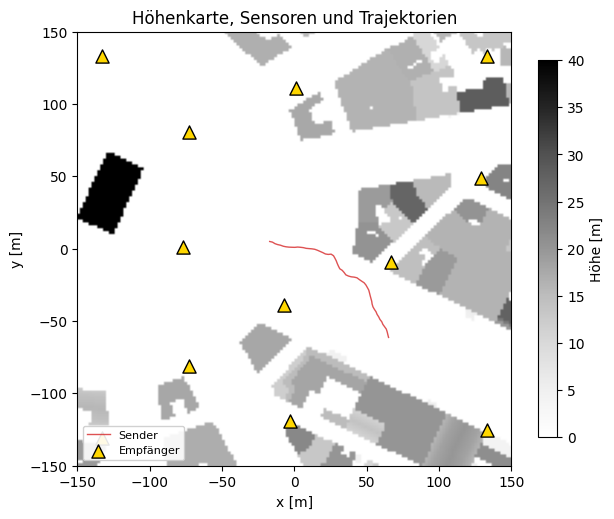

In [ ]:
ext = [-CFG["roi_half"], CFG["roi_half"], -CFG["roi_half"], CFG["roi_half"]]
fig, ax = plt.subplots(figsize=(7, 7))
im = ax.imshow(H, origin="lower", extent=ext, cmap="Greys", vmax=40)
for k in range(CFG["n_tx"]):
    ax.plot(*tx_xy[k].T, lw=1, color="tab:red", alpha=0.8, label="Sender")
ax.scatter(*sensor_xy.T, marker="^", s=90, c="gold", edgecolors="k", zorder=3, label="Empfänger")
ax.set(xlabel="x [m]", ylabel="y [m]", title="Höhenkarte, Sensoren und Trajektorien")
fig.colorbar(im, ax=ax, shrink=0.7, label="Höhe [m]"); ax.legend(loc="lower left", fontsize=8, framealpha=0.9)
plt.show()

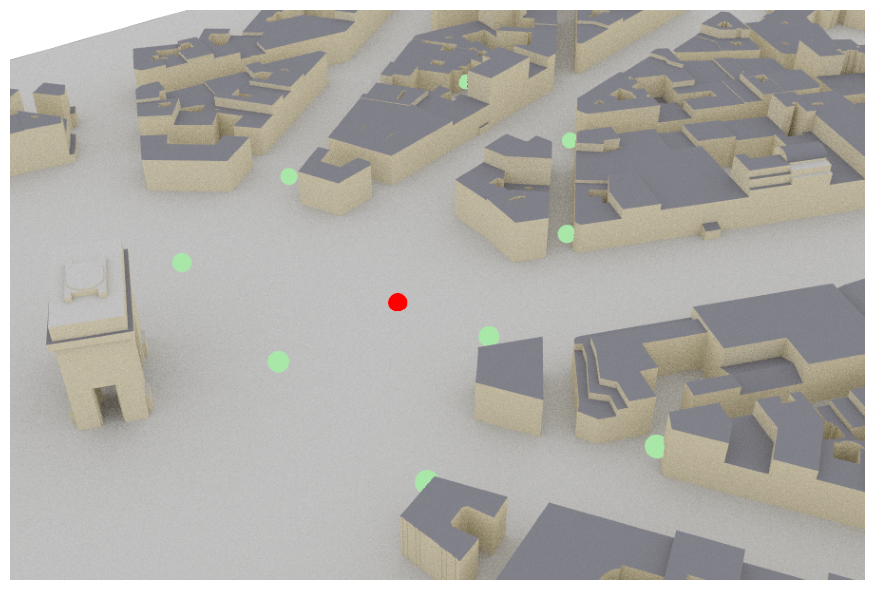

In [ ]:
for i, p in enumerate(sensor_pos):
    scene.add(Receiver(f"sensor_{i}", position=mi.Point3f(*map(float, p)), display_radius=4.0))
for k in range(CFG["n_tx"]):
    scene.add(Transmitter(f"tx_{k}", position=mi.Point3f(*map(float, tx_pos[k, 0])),
                          display_radius=4.0))
cam = Camera(position=[-220, -260, 260], look_at=[0, 0, 0])
scene.render(camera=cam, resolution=(900, 600), num_samples=64 if HAS_GPU else 16);

## 6. Raytracing

### Pfadgewinn
Für jede Verbindung liefert Sionna komplexe Pfadkoeffizienten $a_i$. Der Pfadgewinn ist die Summe aus den Pfadkoeffizienten

$$G = \sum_i |a_i|^2,$$

Die Koeffizienten sind unabhängig von der Sendeleistung. Die wird in Abschnitt 7 addiert.

In [ ]:
solver = PathSolver()

def solve(scene, **kw):
    return solver(scene, max_depth=CFG["max_depth"], **kw)

def link_stats(paths):
    # Gibt Pfadgewinn [rx, tx], LoS-Flag und Pfadanzahl zurück
    a_re, a_im = paths.a                                    # [rx, rx_ant, tx, tx_ant, P]
    g = (a_re.numpy() ** 2 + a_im.numpy() ** 2).sum(axis=(1, 3, 4))
    valid = paths.valid.numpy().astype(bool)                # [rx, tx, P]
    inter = paths.interactions.numpy()                      # [depth, rx, tx, P]
    los = (valid & (inter == 0).all(axis=0)).any(-1)
    return g, los, valid.sum(-1)

def clear_devices(scene):
    for n in list(scene.transmitters) + list(scene.receivers):
        scene.remove(n)

def P3(p):
    return mi.Point3f(*map(float, p))

test_t = tx_pos[0, :]
near = np.unique(np.linalg.norm(test_t[:1, None] - sensor_pos[None], axis=-1).argmin(1))
test_s = sensor_pos[near]
clear_devices(scene)
for i, p in enumerate(test_t): scene.add(Transmitter(f"t{i}", position=P3(p)))
for j, p in enumerate(test_s): scene.add(Receiver(f"s{j}", position=P3(p)))
g_fwd, _, _ = link_stats(solve(scene))                      # [sensor, tx]
db = lambda g: np.where(g > 0, 10 * np.log10(np.maximum(g, 1e-30)), np.nan)
print("Pfadgewinn zwischen Sender und nächstem Receiver [dB]:\n", np.round(db(g_fwd), 1))
test_t = tx_pos[:1, 0]
test_s = sensor_pos
clear_devices(scene)
for i, p in enumerate(test_t): scene.add(Transmitter(f"t{i}", position=P3(p)))
for j, p in enumerate(test_s): scene.add(Receiver(f"s{j}", position=P3(p)))
g_fwd, _, _ = link_stats(solve(scene))                      # [sensor, tx]
db = lambda g: np.where(g > 0, 10 * np.log10(np.maximum(g, 1e-30)), np.nan)
print("Pfadgewinn zwischen Sender und allen Receivern [dB]:\n", np.round(db(g_fwd), 1))


Pfadgewinn zwischen Sender und nächstem Receiver [dB]:
 [[-67.8 -67.3 -67.1 -67.3 -67.2 -67.1 -66.9 -66.9 -66.9 -67.  -67.1 -67.2
  -67.3 -67.3 -67.4 -67.5 -67.5 -67.7 -67.8 -67.8 -67.7 -67.8 -68.2 -68.1
  -68.1 -68.  -68.1 -68.1 -68.  -67.8 -67.8 -67.2 -68.4 -68.4 -67.7 -67.9
  -68.  -68.1 -68.2 -68.3 -68.4 -68.4 -68.5 -68.3 -68.5 -69.6 -69.6 -69.9
  -69.7 -68.8 -68.8 -70.1 -70.4 -70.6 -70.7 -70.8 -72.  -72.1 -72.2 -72.2]]
Pfadgewinn zwischen Sender und allen Receivern [dB]:
 [[-79. ]
 [-76.6]
 [-78.9]
 [  nan]
 [-70.7]
 [-89. ]
 [-76.8]
 [-81.2]
 [-80.1]
 [-67.8]
 [-73.1]
 [-74.5]]


In [ ]:
def compute_links(scene, sensor_pos, targets, batch=8):
    clear_devices(scene)
    for j, s in enumerate(sensor_pos):
        scene.add(Receiver(f"sensor_{j}", position=P3(s)))
    for i, t in enumerate(targets):
        scene.add(Transmitter(f"target_{i}", position=P3(t)))

    g, los, npaths = link_stats(solve(scene))
    return g, los, npaths

N, T, S = CFG["n_tx"], CFG["n_steps"], CFG["n_sensors"]
G, LOS, NP = compute_links(scene, sensor_pos, tx_pos.reshape(-1, 3))
path_gain = G.reshape(N, S, T)
los = LOS.reshape(N, S, T)
num_paths = NP.reshape(N, S, T)
path_gain_db = db(path_gain)                                 # NaN: kein Pfad gefunden
print(f"Verbindungen ohne Pfad: {np.isnan(path_gain_db).mean():.1%}, LoS-Anteil: {los.mean():.1%}")

Verbindungen ohne Pfad: 9.2%, LoS-Anteil: 52.2%


## 7. RSSI-Modell

$$\text{RSSI} = P_{tx} + 10\log_{10} G$$

Werte unter der Empfängerempfindlichkeit gelten als nicht detektiert (`NaN`, `detected=False`).

In [ ]:
def make_rssi(path_gain_db, cfg, rng):
    r = cfg["tx_power_dbm"] + path_gain_db
    det = np.isfinite(r) & (r >= cfg["sensitivity_dbm"])
    return np.where(det, r, np.nan), det

rssi_dbm, detected = make_rssi(path_gain_db, CFG, rng)
print(rssi_dbm.shape)

n_det = detected.sum(-1)
print("Anteil detektierter Verbindungen:", f"{detected.mean():.1%}")
print("Valide Messungen pro Sensor:", n_det)

(1, 12, 60)
Anteil detektierter Verbindungen: 90.8%
Valide Messungen pro Sensor: [[60 60 49 11 60 60 60 56 58 60 60 60]]


(1, 12, 60)


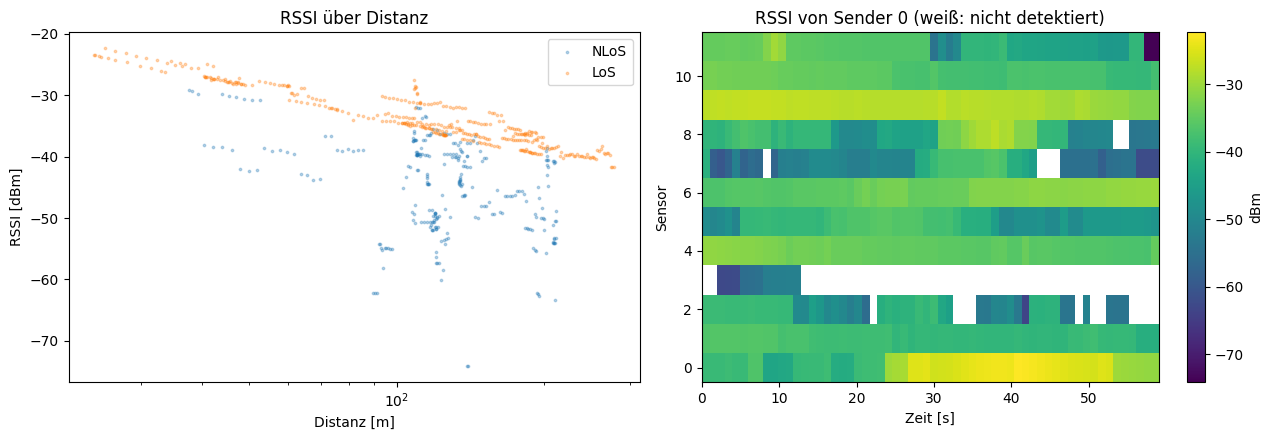

In [ ]:
d3 = np.linalg.norm(tx_pos[:, None,:, :] - sensor_pos[None, :, None,:], axis=-1)   # [N, S, T]
print(d3.shape)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
m = detected
axs[0].scatter(d3[m & ~los], rssi_dbm[m & ~los], s=3, alpha=0.3, label="NLoS")
axs[0].scatter(d3[m & los], rssi_dbm[m & los], s=3, alpha=0.3, label="LoS")
dd = np.logspace(0.5, np.log10(d3.max()), 100)
lam = 3e8 / CFG["frequency_hz"]
axs[0].set(xscale="log", xlabel="Distanz [m]", ylabel="RSSI [dBm]", title="RSSI über Distanz"); axs[0].legend()

k = 0
im = axs[1].imshow(rssi_dbm[k], aspect="auto", origin="lower", cmap="viridis",
                   extent=[0, time_s[-1], -0.5, S - 0.5])
axs[1].set(xlabel="Zeit [s]", ylabel="Sensor", title=f"RSSI von Sender {k} (weiß: nicht detektiert)")
fig.colorbar(im, ax=axs[1], label="dBm")
plt.tight_layout(); plt.show()

## 8. Export als HDF5

| Pfad | Form | Inhalt |
|---|---|---|
| `sensors/positions` | [S, 3] | Sensorpositionen in m |
| `tx/positions` | [N, T, 3] | Senderpositionen (Ground Truth) |
| `tx/velocities` | [N, T, 3] | Geschwindigkeit in m/s |
| `tx/speed` | [N] | Bewegungsparameter |
| `tx/time_s` | [T] | Zeitachse |
| `measurements/rssi_dbm` | [N, S, T] | RSSI (`NaN` = keine Messung) |
| `map/height`, `map/x`, `map/y` | | Höhenkarte |

Die Aufteilung erfolgt nach Sender, damit Positionen einer Trajektorie nicht gleichzeitig in Training und Test liegen.

In [ ]:
perm = rng.permutation(N)
n_test = max(1, int(round(CFG["test_fraction"] * N)))
test_tx, train_tx = np.sort(perm[:n_test]), np.sort(perm[n_test:])

def save_h5(path):
    with h5py.File(path, "w") as f:
        for k_, v_ in CFG.items():
            f.attrs[k_] = v_ if not isinstance(v_, tuple) else np.array(v_)
        f.attrs["sionna_rt_version"] = rt.__version__
        f.attrs["mitsuba_variant"] = mi.variant()
        kw = dict(compression="gzip", compression_opts=4)
        f["sensors/positions"] = sensor_pos
        f["tx/positions"] = tx_pos
        f["tx/velocities"] = tx_vel
        f["tx/speed"] = np.array(tx_speed)
        f["tx/time_s"] = time_s
        f.create_dataset("measurements/rssi_dbm", data=rssi_dbm.astype(np.float32), **kw)
        f.create_dataset("map/height", data=H.astype(np.float32), **kw)
        f["map/x"] = grid_c; f["map/y"] = grid_c
        f["split/train_tx"] = train_tx; f["split/test_tx"] = test_tx

save_h5(CFG["out_file"])
print(f"{CFG['out_file']}: {os.path.getsize(CFG['out_file']) / 1e6:.2f} MB")

rssi_dataset.h5: 0.03 MB


In [ ]:

with h5py.File(CFG["out_file"], "r") as f:
    sensors = f["sensors/positions"][:, :2]
    true_xy = f["tx/positions"][0, :, :2]
    rssi    = f["measurements/rssi_dbm"][0]
    t       = f["tx/time_s"][()]

print("Sensoren:", sensors.shape, "| RSSI:", rssi.shape)

Sensoren: (12, 2) | RSSI: (12, 60)


## 9. Benchmark: Triangulation

### 9.1 Freiraummodell

$$\text{RSSI}(d) = P_{tx} + 20\log_{10}\!\left(\frac{\lambda}{4\pi d}\right)
\quad\Rightarrow\quad
\hat d = \frac{\lambda}{4\pi}\,10^{(P_{tx} - \text{RSSI})/20}$$

Der Plot zeigt die Messungen gegen die wahre Distanz. Punkte unter der Kurve sind abgeschattet; ihre Distanz wird überschätzt.

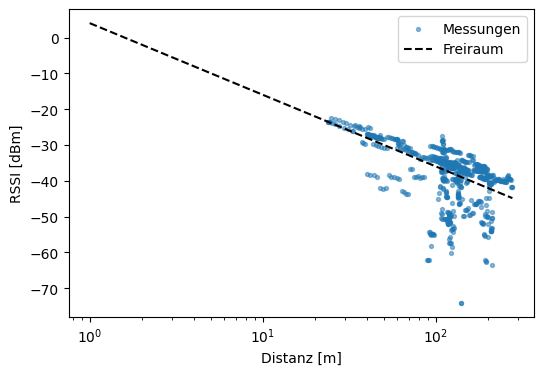

In [ ]:
lam = 3e8 / CFG["frequency_hz"]
P_tx = CFG["tx_power_dbm"]

def rssi_free_space(d):
    return P_tx + 20 * np.log10(lam / (4 * np.pi * d))

def rssi_to_dist(r):
    return lam / (4 * np.pi) * 10 ** ((P_tx - r) / 20)

dist = np.linalg.norm(true_xy[None, :, :] - sensors[:, None, :], axis=-1)   # [S, T]
m = ~np.isnan(rssi)
dd = np.linspace(1, dist.max(), 200)
plt.figure(figsize=(6, 4))
plt.scatter(dist[m], rssi[m], s=8, alpha=0.5, label="Messungen")
plt.plot(dd, rssi_free_space(dd), "k--", label="Freiraum")
plt.xscale("log"); plt.xlabel("Distanz [m]"); plt.ylabel("RSSI [dBm]"); plt.legend(); plt.show()

### 9.2 Trilateration

Distanz pro Sensor: $\hat d_i = 10^{(A - \text{RSSI}_i)/(10 n)}$.

Gesucht ist die Position $\mathbf p$, deren Abstände zu den Sensoren am besten zu $\hat d_i$ passen:

$$\hat{\mathbf p} = \arg\min_{\mathbf p} \sum_i \left(\log_{10}\lVert \mathbf p - \mathbf s_i \rVert - \log_{10}\hat d_i\right)^2$$

Der Vergleich erfolgt logarithmisch, weil der Distanzfehler mit der Distanz wächst: 10 dB Abschattung verfälschen 20 m und 200 m um denselben Faktor. Gelöst mit `scipy.optimize.least_squares`, beschränkt auf das Untersuchungsgebiet. Startwert ist der Mittelpunkt der messenden Sensoren. Zeitschritte mit weniger als drei Messungen werden übersprungen.

Als einfachste Referenz dient zusätzlich die Position des Sensors mit dem stärksten RSSI.

In [ ]:
def trilaterate(s, d, lim=CFG["roi_half"]):
    residual = lambda p: np.log10(np.linalg.norm(s - p, axis=1) + 1e-3) - np.log10(d)
    return least_squares(residual, x0=s.mean(axis=0), bounds=([-lim, -lim], [lim, lim])).x

d_hat = rssi_to_dist(rssi)                      # [T, S], NaN = keine Messung
est = np.full((len(t), 2), np.nan)
for i in range(len(t)):
    ok = ~np.isnan(rssi[:, i])
    if ok.sum() >= 3:
        est[i] = trilaterate(sensors[ok], d_hat[ok, i])

### 9.3 Ergebnis

Die Schätzungen erscheinen Zeitschritt für Zeitschritt. Rote Linien: Von jedem messenden Sensor in Richtung der wahren Senderposition, Länge = geschätzte Distanz $\hat d_i$. Endet eine Linie vor dem Sender, ist die Distanz unterschätzt; reicht sie darüber hinaus, überschätzt.

In [ ]:
err = np.linalg.norm(est - true_xy, axis=1)
print(f"Mittel {np.nanmean(err):.2f} m | Median {np.nanmedian(err):.1f} m | "
      f"geschätzt: {np.isfinite(err).sum()}/{len(err)} Zeitschritte")

Mittel 40.97 m | Median 32.7 m | geschätzt: 60/60 Zeitschritte


In [ ]:
import matplotlib.patheffects as pe
from IPython.display import HTML
from matplotlib.animation import FuncAnimation
from matplotlib.colors import Normalize

dist_err = d_hat - dist                          # [T, S] Distanzfehler in m
cmap, norm = plt.get_cmap("coolwarm"), Normalize(-100, 100)

fig, (ax, ax_e) = plt.subplots(1, 2, figsize=(13, 5), dpi=80)
ax.imshow(H, origin="lower", extent=ext, cmap="Greys", vmax=40)
ax.scatter(*sensors.T, marker="^", s=70, c="gold", edgecolors="k", zorder=4, label="Sensoren")
ax.set(xlim=ext[:2], ylim=ext[2:], xlabel="x [m]", ylabel="y [m]")

true_line, = ax.plot([], [], "k-", lw=2, label="Wahr")
true_dot, = ax.plot([], [], "ko", ms=8)
est_trail, = ax.plot([], [], ".", ms=5, alpha=0.4, c="C0")
est_dot, = ax.plot([], [], "o", ms=9, mec="k", c="C0", zorder=5, label="Schätzung")
outline = [pe.Stroke(linewidth=3.5, foreground="k"), pe.Normal()]   # dunkler Rand
dist_lines = [ax.plot([], [], "-", lw=2, path_effects=outline)[0] for _ in sensors]
ax.plot([], [], "-", c="gray", lw=2, label="geschätzte Distanz")
fig.colorbar(plt.cm.ScalarMappable(norm, cmap), ax=ax, shrink=0.8, extend="both",
             label="Distanzfehler $\\hat d - d$ [m]")
ax.legend(loc="lower left", fontsize=7)

err_line, = ax_e.plot([], [], ".-", c="C0")
ax_e.set(xlim=(t[0], t[-1]), ylim=(0, 1.05 * np.nanmax(err)),
         xlabel="Zeit [s]", ylabel="Fehler [m]", title="Lokalisierungsfehler")
plt.tight_layout()

def update(i):
    p = true_xy[i]
    true_line.set_data(*true_xy[:i + 1].T)
    true_dot.set_data([p[0]], [p[1]])
    est_trail.set_data(*est[:i + 1].T)
    est_dot.set_data([est[i, 0]], [est[i, 1]])
    err_line.set_data(t[:i + 1], err[:i + 1])
    # Linie von jedem Sensor in Richtung der wahren Position, Länge = geschätzte Distanz
    for j, (s, line) in enumerate(zip(sensors, dist_lines)):
        if np.isnan(d_hat[j, i]):
            line.set_data([], [])
            continue
        u = (p - s) / np.linalg.norm(p - s)
        end = s + d_hat[j, i] * u
        line.set_data([s[0], end[0]], [s[1], end[1]])
        line.set_color(cmap(norm(dist_err[j, i])))
    ax.set_title(f"Trajektorie, t = {t[i]:.0f} s")
    return []

anim = FuncAnimation(fig, update, frames=len(t), interval=300)
plt.close(fig)
# anim.save("trilateration.gif", writer="pillow", fps=3)   # optional als GIF
HTML(anim.to_jshtml())

## 10. Hinweise

Wir nehmen hier einmal vereinfacht an, dass wir die Sendeleistung kennen. Das ist eigentlich nicht der Fall. Das macht die ganze Sache nochmal ein bisschen komplizierter. Wenn wir genügend Sensoren haben, ist das aber nicht notwendig, weil wir diese in eine LGS auch als Parameter estimaten können.

Trotzdem funktionieren die Ergebnisse natürlich nur sehr begrenzt. Das liegt an verschiedenen Dingen. Eine Sache die vermutlich schon eine einfache Verbesserung ist, wäre ein weighting bei der Triangulation zu machen. Also nähere Sensoren höher gewichten, usw.

Generell ist das mit klassischen Methoden in Mehrwegeumgebungen aber immer relativ flawed, da die RSSI --> Distanz Schätzung nicht akkurat genug ist. Deshalb wollen wir dafür neuronale Netze verwenden.
